# 📊 Phân Tích Dữ Liệu Các Yếu Tố Ảnh Hưởng Đến Kết Quả Học Tập Của Sinh Viên
## (Student Performance Factors - Exploratory Data Analysis)

---

**Mục tiêu:**
1. Tải và mô tả tập dữ liệu
2. Kiểm tra chất lượng dữ liệu (giá trị thiếu, trùng lặp, kiểu dữ liệu, giá trị bất thường)
3. Thực hiện thống kê mô tả
4. Tạo các hình ảnh trực quan có ý nghĩa
5. Nghiên cứu mối quan hệ giữa các biến

**Tập dữ liệu:** `StudentPerformanceFactors.csv` — chứa thông tin về các yếu tố ảnh hưởng đến điểm thi của sinh viên.

## 1. Import thư viện và tải dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Cấu hình hiển thị
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

print("✅ Đã import thành công tất cả thư viện!")

✅ Đã import thành công tất cả thư viện!


In [2]:
# Tải dữ liệu
df = pd.read_csv('StudentPerformanceFactors.csv')

print(f"📁 Kích thước tập dữ liệu: {df.shape[0]} dòng × {df.shape[1]} cột")
print(f"📊 Dung lượng bộ nhớ: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")
print()
print("🔍 5 dòng đầu tiên:")
df.head()

📁 Kích thước tập dữ liệu: 6607 dòng × 20 cột
📊 Dung lượng bộ nhớ: 4887.5 KB

🔍 5 dòng đầu tiên:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 2. Mô tả tổng quan tập dữ liệu

In [3]:
# Thông tin tổng quan về tập dữ liệu
print("=" * 70)
print("📋 THÔNG TIN TỔNG QUAN VỀ TẬP DỮ LIỆU")
print("=" * 70)
print()
df.info()

📋 THÔNG TIN TỔNG QUAN VỀ TẬP DỮ LIỆU

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non

In [4]:
# Phân loại các biến
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()

print("📐 CÁC BIẾN SỐ (Numeric):")
for i, col in enumerate(numeric_cols, 1):
    print(f"   {i}. {col}")

print(f"\n📝 CÁC BIẾN PHÂN LOẠI (Categorical):")
for i, col in enumerate(categorical_cols, 1):
    unique_vals = df[col].dropna().unique()
    print(f"   {i}. {col}: {list(unique_vals)}")

print(f"\n→ Tổng: {len(numeric_cols)} biến số + {len(categorical_cols)} biến phân loại = {len(df.columns)} biến")

📐 CÁC BIẾN SỐ (Numeric):
   1. Hours_Studied
   2. Attendance
   3. Sleep_Hours
   4. Previous_Scores
   5. Tutoring_Sessions
   6. Physical_Activity
   7. Exam_Score

📝 CÁC BIẾN PHÂN LOẠI (Categorical):
   1. Parental_Involvement: ['Low', 'Medium', 'High']
   2. Access_to_Resources: ['High', 'Medium', 'Low']
   3. Extracurricular_Activities: ['No', 'Yes']
   4. Motivation_Level: ['Low', 'Medium', 'High']
   5. Internet_Access: ['Yes', 'No']
   6. Family_Income: ['Low', 'Medium', 'High']
   7. Teacher_Quality: ['Medium', 'High', 'Low']
   8. School_Type: ['Public', 'Private']
   9. Peer_Influence: ['Positive', 'Negative', 'Neutral']
   10. Learning_Disabilities: ['No', 'Yes']
   11. Parental_Education_Level: ['High School', 'College', 'Postgraduate']
   12. Distance_from_Home: ['Near', 'Moderate', 'Far']
   13. Gender: ['Male', 'Female']

→ Tổng: 7 biến số + 13 biến phân loại = 20 biến


## 3. Kiểm tra chất lượng dữ liệu

### 3.1. Giá trị thiếu (Missing Values)

🔍 KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES)

⚠️ Các cột có giá trị thiếu:
                          Số lượng thiếu  Tỷ lệ (%)
Parental_Education_Level              90       1.36
Teacher_Quality                       78       1.18
Distance_from_Home                    67       1.01

→ Tổng cộng 3 cột có giá trị thiếu


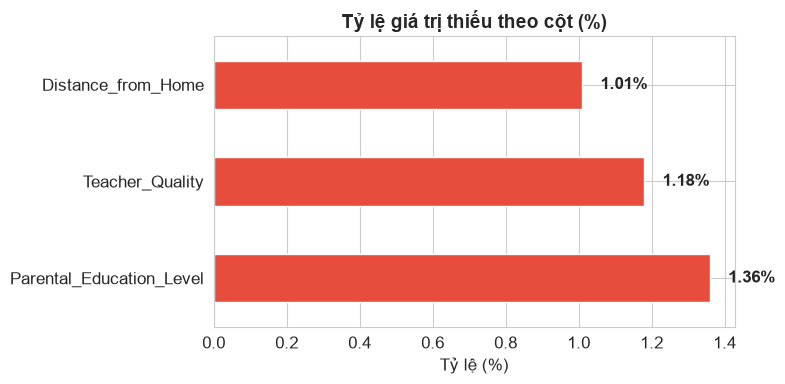

In [5]:
# Kiểm tra giá trị thiếu
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Số lượng thiếu': missing,
    'Tỷ lệ (%)': missing_pct
}).sort_values('Số lượng thiếu', ascending=False)

print("=" * 50)
print("🔍 KIỂM TRA GIÁ TRỊ THIẾU (MISSING VALUES)")
print("=" * 50)
print()

has_missing = missing_df[missing_df['Số lượng thiếu'] > 0]
if len(has_missing) > 0:
    print("⚠️ Các cột có giá trị thiếu:")
    print(has_missing.to_string())
    print(f"\n→ Tổng cộng {len(has_missing)} cột có giá trị thiếu")
else:
    print("✅ Không có giá trị thiếu trong tập dữ liệu!")

# Trực quan hóa giá trị thiếu
if len(has_missing) > 0:
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in missing.values]
    has_missing['Tỷ lệ (%)'].plot(kind='barh', color='#e74c3c', ax=ax)
    ax.set_title('Tỷ lệ giá trị thiếu theo cột (%)', fontweight='bold')
    ax.set_xlabel('Tỷ lệ (%)')
    for i, v in enumerate(has_missing['Tỷ lệ (%)'].values):
        ax.text(v + 0.05, i, f'{v}%', va='center', fontweight='bold')
    plt.tight_layout()
    plt.show()

### 3.2. Giá trị trùng lặp (Duplicates)

In [6]:
# Kiểm tra giá trị trùng lặp
dup_count = df.duplicated().sum()

print("=" * 50)
print("🔍 KIỂM TRA GIÁ TRỊ TRÙNG LẶP (DUPLICATES)")
print("=" * 50)
print()
if dup_count == 0:
    print(f"✅ Không có dòng trùng lặp trong tập dữ liệu ({dup_count}/{len(df)} dòng)")
else:
    print(f"⚠️ Có {dup_count} dòng trùng lặp ({dup_count/len(df)*100:.2f}%)")
    print("\nCác dòng trùng lặp:")
    print(df[df.duplicated(keep=False)].head(10))

🔍 KIỂM TRA GIÁ TRỊ TRÙNG LẶP (DUPLICATES)

✅ Không có dòng trùng lặp trong tập dữ liệu (0/6607 dòng)


### 3.3. Kiểm tra kiểu dữ liệu

In [7]:
# Kiểm tra kiểu dữ liệu
print("=" * 60)
print("🔍 KIỂM TRA KIỂU DỮ LIỆU (DATA TYPES)")
print("=" * 60)
print()

dtype_df = pd.DataFrame({
    'Cột': df.columns,
    'Kiểu dữ liệu': df.dtypes.values,
    'Giá trị duy nhất': [df[col].nunique() for col in df.columns],
    'Ví dụ': [str(df[col].dropna().iloc[0]) for col in df.columns]
})
print(dtype_df.to_string(index=False))

print(f"\n→ Kiểu int64: {(df.dtypes == 'int64').sum()} cột")
print(f"→ Kiểu object/string: {len(categorical_cols)} cột")

🔍 KIỂM TRA KIỂU DỮ LIỆU (DATA TYPES)

                       Cột Kiểu dữ liệu  Giá trị duy nhất       Ví dụ
             Hours_Studied        int64                41          23
                Attendance        int64                41          84
      Parental_Involvement          str                 3         Low
       Access_to_Resources          str                 3        High
Extracurricular_Activities          str                 2          No
               Sleep_Hours        int64                 7           7
           Previous_Scores        int64                51          73
          Motivation_Level          str                 3         Low
           Internet_Access          str                 2         Yes
         Tutoring_Sessions        int64                 9           0
             Family_Income          str                 3         Low
           Teacher_Quality          str                 3      Medium
               School_Type          str             

### 3.4. Phát hiện giá trị bất thường (Outliers)

🔍 PHÁT HIỆN GIÁ TRỊ BẤT THƯỜNG (OUTLIERS) - PHƯƠNG PHÁP IQR

             Biến   Q1   Q3  IQR  Giới hạn dưới  Giới hạn trên  Số outliers  Tỷ lệ (%)
    Hours_Studied 16.0 24.0  8.0            4.0           36.0           43       0.65
       Attendance 70.0 90.0 20.0           40.0          120.0            0       0.00
      Sleep_Hours  6.0  8.0  2.0            3.0           11.0            0       0.00
  Previous_Scores 63.0 88.0 25.0           25.5          125.5            0       0.00
Tutoring_Sessions  1.0  2.0  1.0           -0.5            3.5          430       6.51
Physical_Activity  2.0  4.0  2.0           -1.0            7.0            0       0.00
       Exam_Score 65.0 69.0  4.0           59.0           75.0          104       1.57


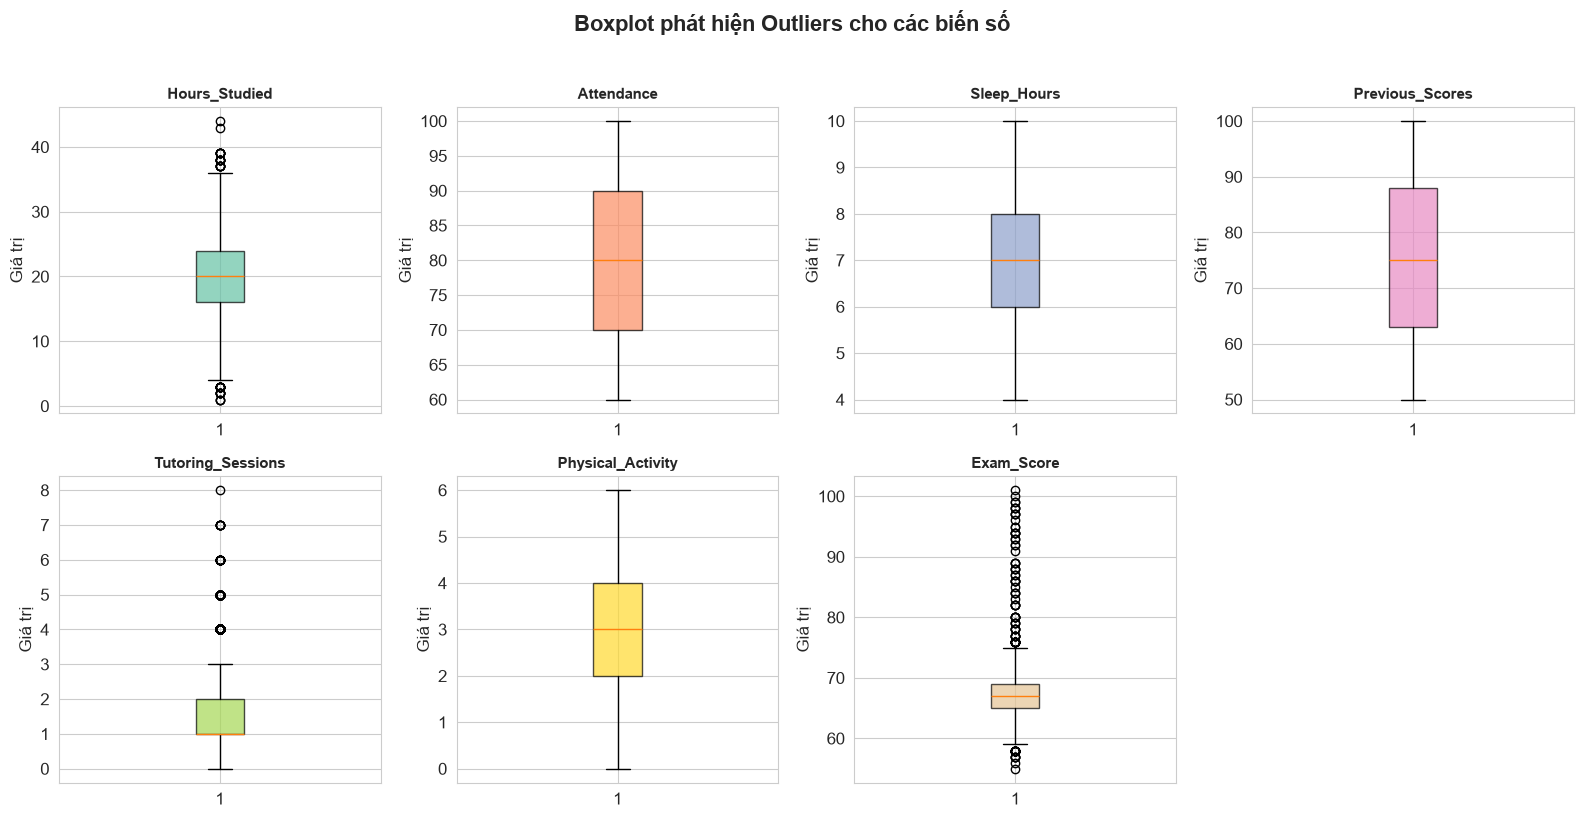

In [8]:
# Phát hiện outliers bằng phương pháp IQR
print("=" * 70)
print("🔍 PHÁT HIỆN GIÁ TRỊ BẤT THƯỜNG (OUTLIERS) - PHƯƠNG PHÁP IQR")
print("=" * 70)
print()

outlier_summary = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_summary.append({
        'Biến': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Giới hạn dưới': lower,
        'Giới hạn trên': upper,
        'Số outliers': len(outliers),
        'Tỷ lệ (%)': round(len(outliers)/len(df)*100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index=False))

# Boxplot cho tất cả biến số
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
colors = sns.color_palette("Set2", len(numeric_cols))

for i, col in enumerate(numeric_cols):
    if i < len(axes):
        bp = axes[i].boxplot(df[col].dropna(), patch_artist=True, 
                            boxprops=dict(facecolor=colors[i], alpha=0.7))
        axes[i].set_title(col, fontweight='bold', fontsize=11)
        axes[i].set_ylabel('Giá trị')

# Ẩn subplot thừa
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplot phát hiện Outliers cho các biến số', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. Thống kê mô tả (Descriptive Statistics)

### 4.1. Thống kê mô tả cho biến số

In [9]:
# Thống kê mô tả cho biến số
print("=" * 80)
print("📊 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN SỐ")
print("=" * 80)
print()

desc = df[numeric_cols].describe().T
desc['median'] = df[numeric_cols].median()
desc['skew'] = df[numeric_cols].skew().round(3)
desc['kurtosis'] = df[numeric_cols].kurtosis().round(3)
desc = desc[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'skew', 'kurtosis']]
desc.columns = ['Số lượng', 'Trung bình', 'Trung vị', 'Độ lệch chuẩn', 'Min', 'Q1', 'Q2', 'Q3', 'Max', 'Skewness', 'Kurtosis']
print(desc.round(2).to_string())

print("\n📝 Nhận xét:")
for col in numeric_cols:
    skew = df[col].skew()
    if abs(skew) < 0.5:
        dist = "phân phối gần đối xứng"
    elif skew > 0:
        dist = "lệch phải (right-skewed)"
    else:
        dist = "lệch trái (left-skewed)"
    print(f"   • {col}: {dist} (skewness = {skew:.3f})")

📊 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN SỐ

                   Số lượng  Trung bình  Trung vị  Độ lệch chuẩn   Min    Q1    Q2    Q3    Max  Skewness  Kurtosis
Hours_Studied        6607.0       19.98      20.0           5.99   1.0  16.0  20.0  24.0   44.0      0.01      0.02
Attendance           6607.0       79.98      80.0          11.55  60.0  70.0  80.0  90.0  100.0      0.01     -1.19
Sleep_Hours          6607.0        7.03       7.0           1.47   4.0   6.0   7.0   8.0   10.0     -0.02     -0.50
Previous_Scores      6607.0       75.07      75.0          14.40  50.0  63.0  75.0  88.0  100.0     -0.00     -1.19
Tutoring_Sessions    6607.0        1.49       1.0           1.23   0.0   1.0   1.0   2.0    8.0      0.82      0.64
Physical_Activity    6607.0        2.97       3.0           1.03   0.0   2.0   3.0   4.0    6.0     -0.03     -0.06
Exam_Score           6607.0       67.24      67.0           3.89  55.0  65.0  67.0  69.0  101.0      1.64     10.58

📝 Nhận xét:
   • Hours_Studied: phân 

### 4.2. Thống kê mô tả cho biến phân loại

In [10]:
# Thống kê mô tả cho biến phân loại
print("=" * 70)
print("📊 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN PHÂN LOẠI")
print("=" * 70)
print()

for col in categorical_cols:
    print(f"\n📌 {col}:")
    counts = df[col].value_counts(dropna=False)
    pcts = df[col].value_counts(normalize=True, dropna=False) * 100
    summary = pd.DataFrame({'Số lượng': counts, 'Tỷ lệ (%)': pcts.round(2)})
    print(summary.to_string())
    print(f"   → Mode: {df[col].mode()[0]}")
    print("-" * 40)

📊 THỐNG KÊ MÔ TẢ CHO CÁC BIẾN PHÂN LOẠI


📌 Parental_Involvement:
                      Số lượng  Tỷ lệ (%)
Parental_Involvement                     
Medium                    3362      50.89
High                      1908      28.88
Low                       1337      20.24
   → Mode: Medium
----------------------------------------

📌 Access_to_Resources:
                     Số lượng  Tỷ lệ (%)
Access_to_Resources                     
Medium                   3319      50.23
High                     1975      29.89
Low                      1313      19.87
   → Mode: Medium
----------------------------------------

📌 Extracurricular_Activities:
                            Số lượng  Tỷ lệ (%)
Extracurricular_Activities                     
Yes                             3938       59.6
No                              2669       40.4
   → Mode: Yes
----------------------------------------

📌 Motivation_Level:
                  Số lượng  Tỷ lệ (%)
Motivation_Level                     
M

## 5. Trực quan hóa dữ liệu (Data Visualization)

### 📊 Hình 1: Phân phối điểm thi (Exam Score Distribution)

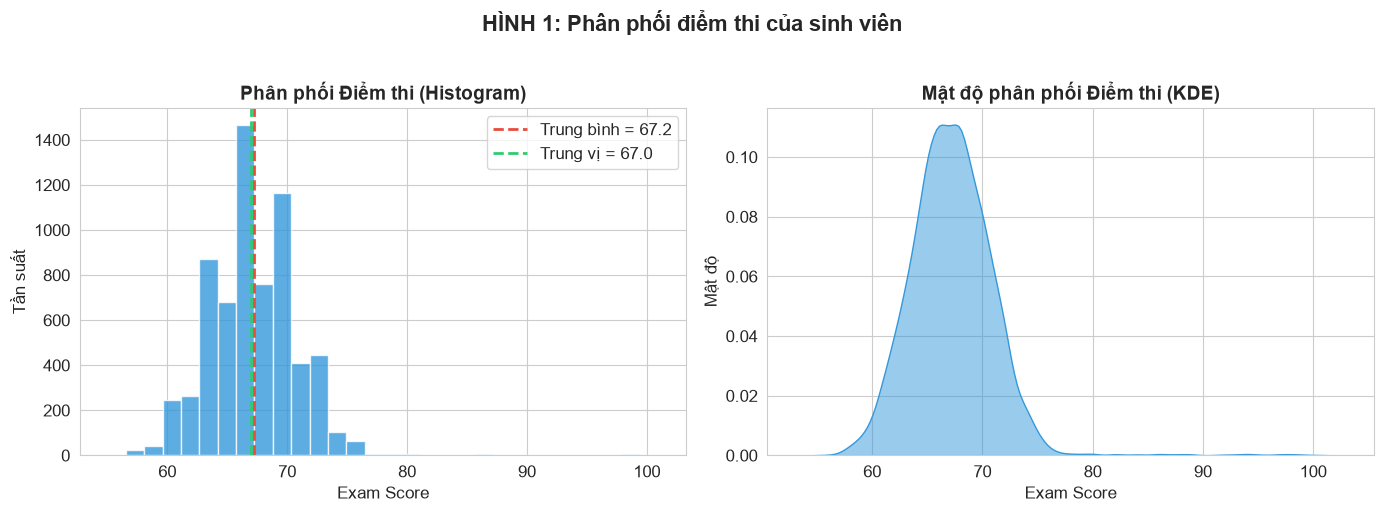


📝 Nhận xét: Điểm thi có phân phối gần chuẩn với trung bình 67.2 và độ lệch chuẩn 3.9. Điểm dao động từ 55 đến 101.


In [11]:
# HÌNH 1: Phân phối điểm thi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df['Exam_Score'], bins=30, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(df['Exam_Score'].mean(), color='#e74c3c', linestyle='--', linewidth=2, 
                label=f"Trung bình = {df['Exam_Score'].mean():.1f}")
axes[0].axvline(df['Exam_Score'].median(), color='#2ecc71', linestyle='--', linewidth=2,
                label=f"Trung vị = {df['Exam_Score'].median():.1f}")
axes[0].set_title('Phân phối Điểm thi (Histogram)', fontweight='bold')
axes[0].set_xlabel('Exam Score')
axes[0].set_ylabel('Tần suất')
axes[0].legend()

# KDE plot
sns.kdeplot(data=df, x='Exam_Score', fill=True, color='#3498db', alpha=0.5, ax=axes[1])
axes[1].set_title('Mật độ phân phối Điểm thi (KDE)', fontweight='bold')
axes[1].set_xlabel('Exam Score')
axes[1].set_ylabel('Mật độ')

plt.suptitle('HÌNH 1: Phân phối điểm thi của sinh viên', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\n📝 Nhận xét: Điểm thi có phân phối gần chuẩn với trung bình {df['Exam_Score'].mean():.1f} "
      f"và độ lệch chuẩn {df['Exam_Score'].std():.1f}. "
      f"Điểm dao động từ {df['Exam_Score'].min()} đến {df['Exam_Score'].max()}.")

### 📊 Hình 2: Mối quan hệ giữa Số giờ học & Điểm thi

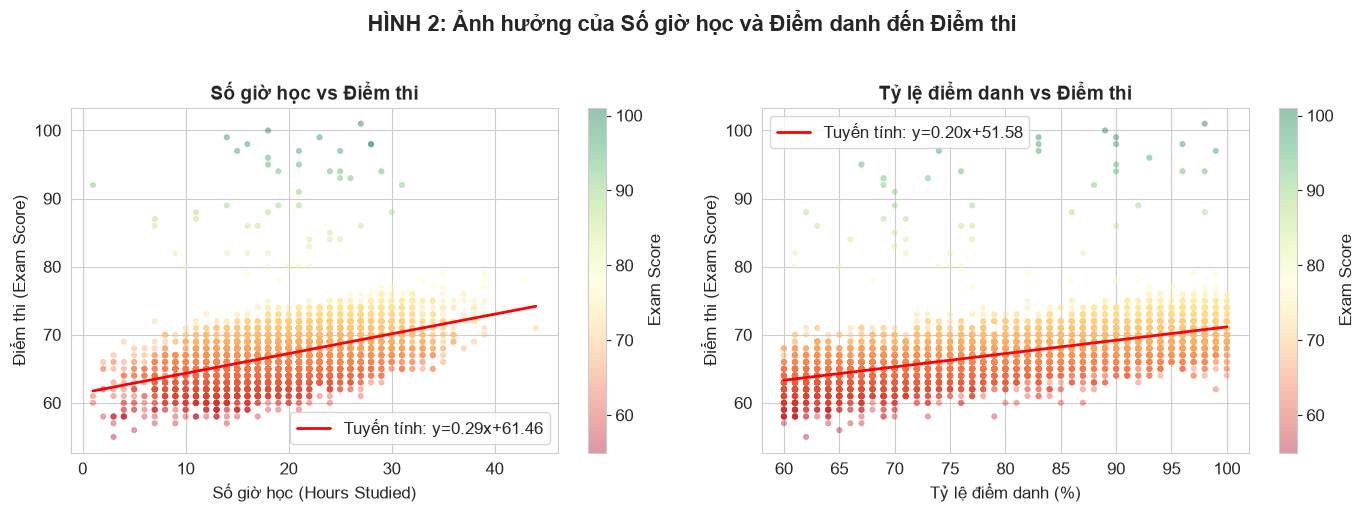


📝 Nhận xét:
   • Hệ số tương quan giữa Số giờ học và Điểm thi: r = 0.4455
   • Hệ số tương quan giữa Điểm danh và Điểm thi: r = 0.5811
   → Cả hai yếu tố đều có mối tương quan thuận với Điểm thi.


In [12]:
# HÌNH 2: Scatter plot - Hours Studied vs Exam Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
scatter = axes[0].scatter(df['Hours_Studied'], df['Exam_Score'], 
                          c=df['Exam_Score'], cmap='RdYlGn', alpha=0.4, s=20, edgecolors='none')
z = np.polyfit(df['Hours_Studied'], df['Exam_Score'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['Hours_Studied'].min(), df['Hours_Studied'].max(), 100)
axes[0].plot(x_line, p(x_line), "r-", linewidth=2, label=f'Tuyến tính: y={z[0]:.2f}x+{z[1]:.2f}')
axes[0].set_title('Số giờ học vs Điểm thi', fontweight='bold')
axes[0].set_xlabel('Số giờ học (Hours Studied)')
axes[0].set_ylabel('Điểm thi (Exam Score)')
axes[0].legend()
plt.colorbar(scatter, ax=axes[0], label='Exam Score')

# Scatter: Attendance vs Exam Score
scatter2 = axes[1].scatter(df['Attendance'], df['Exam_Score'],
                           c=df['Exam_Score'], cmap='RdYlGn', alpha=0.4, s=20, edgecolors='none')
z2 = np.polyfit(df['Attendance'], df['Exam_Score'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(df['Attendance'].min(), df['Attendance'].max(), 100)
axes[1].plot(x_line2, p2(x_line2), "r-", linewidth=2, label=f'Tuyến tính: y={z2[0]:.2f}x+{z2[1]:.2f}')
axes[1].set_title('Tỷ lệ điểm danh vs Điểm thi', fontweight='bold')
axes[1].set_xlabel('Tỷ lệ điểm danh (%)')
axes[1].set_ylabel('Điểm thi (Exam Score)')
axes[1].legend()
plt.colorbar(scatter2, ax=axes[1], label='Exam Score')

plt.suptitle('HÌNH 2: Ảnh hưởng của Số giờ học và Điểm danh đến Điểm thi', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

corr_hours = df['Hours_Studied'].corr(df['Exam_Score'])
corr_attend = df['Attendance'].corr(df['Exam_Score'])
print(f"\n📝 Nhận xét:")
print(f"   • Hệ số tương quan giữa Số giờ học và Điểm thi: r = {corr_hours:.4f}")
print(f"   • Hệ số tương quan giữa Điểm danh và Điểm thi: r = {corr_attend:.4f}")
print(f"   → Cả hai yếu tố đều có mối tương quan thuận với Điểm thi.")

### 📊 Hình 3: Ma trận tương quan (Correlation Heatmap)

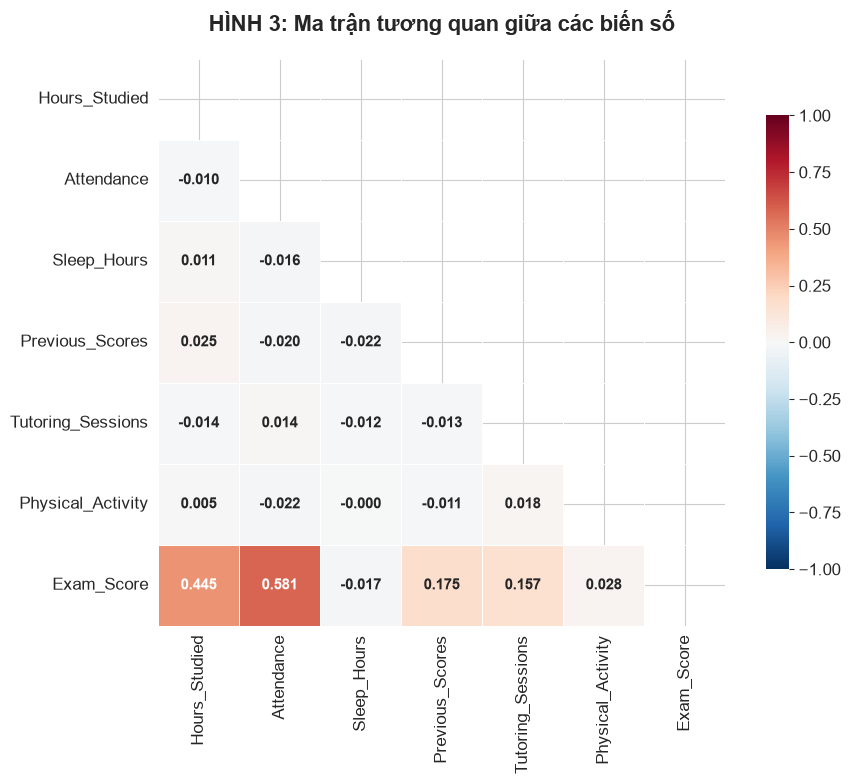


📝 Nhận xét:
   Mức độ tương quan với Exam_Score (theo thứ tự giảm dần):
   • Attendance: r = 0.581 (tương quan thuận, mạnh)
   • Hours_Studied: r = 0.445 (tương quan thuận, trung bình)
   • Previous_Scores: r = 0.175 (tương quan thuận, yếu)
   • Tutoring_Sessions: r = 0.157 (tương quan thuận, yếu)
   • Physical_Activity: r = 0.028 (tương quan thuận, yếu)
   • Sleep_Hours: r = -0.017 (tương quan nghịch, yếu)


In [13]:
# HÌNH 3: Correlation Heatmap
fig, ax = plt.subplots(figsize=(10, 8))

corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.3f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot_kws={"size": 11, "fontweight": "bold"}, ax=ax)

ax.set_title('HÌNH 3: Ma trận tương quan giữa các biến số', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n📝 Nhận xét:")
# Tìm cặp biến có tương quan cao nhất với Exam_Score
exam_corr = corr_matrix['Exam_Score'].drop('Exam_Score').abs().sort_values(ascending=False)
print("   Mức độ tương quan với Exam_Score (theo thứ tự giảm dần):")
for var, val in exam_corr.items():
    direction = "thuận" if corr_matrix.loc[var, 'Exam_Score'] > 0 else "nghịch"
    strength = "mạnh" if val > 0.5 else "trung bình" if val > 0.3 else "yếu"
    print(f"   • {var}: r = {corr_matrix.loc[var, 'Exam_Score']:.3f} (tương quan {direction}, {strength})")

### 📊 Hình 4: Ảnh hưởng của các yếu tố phân loại đến Điểm thi

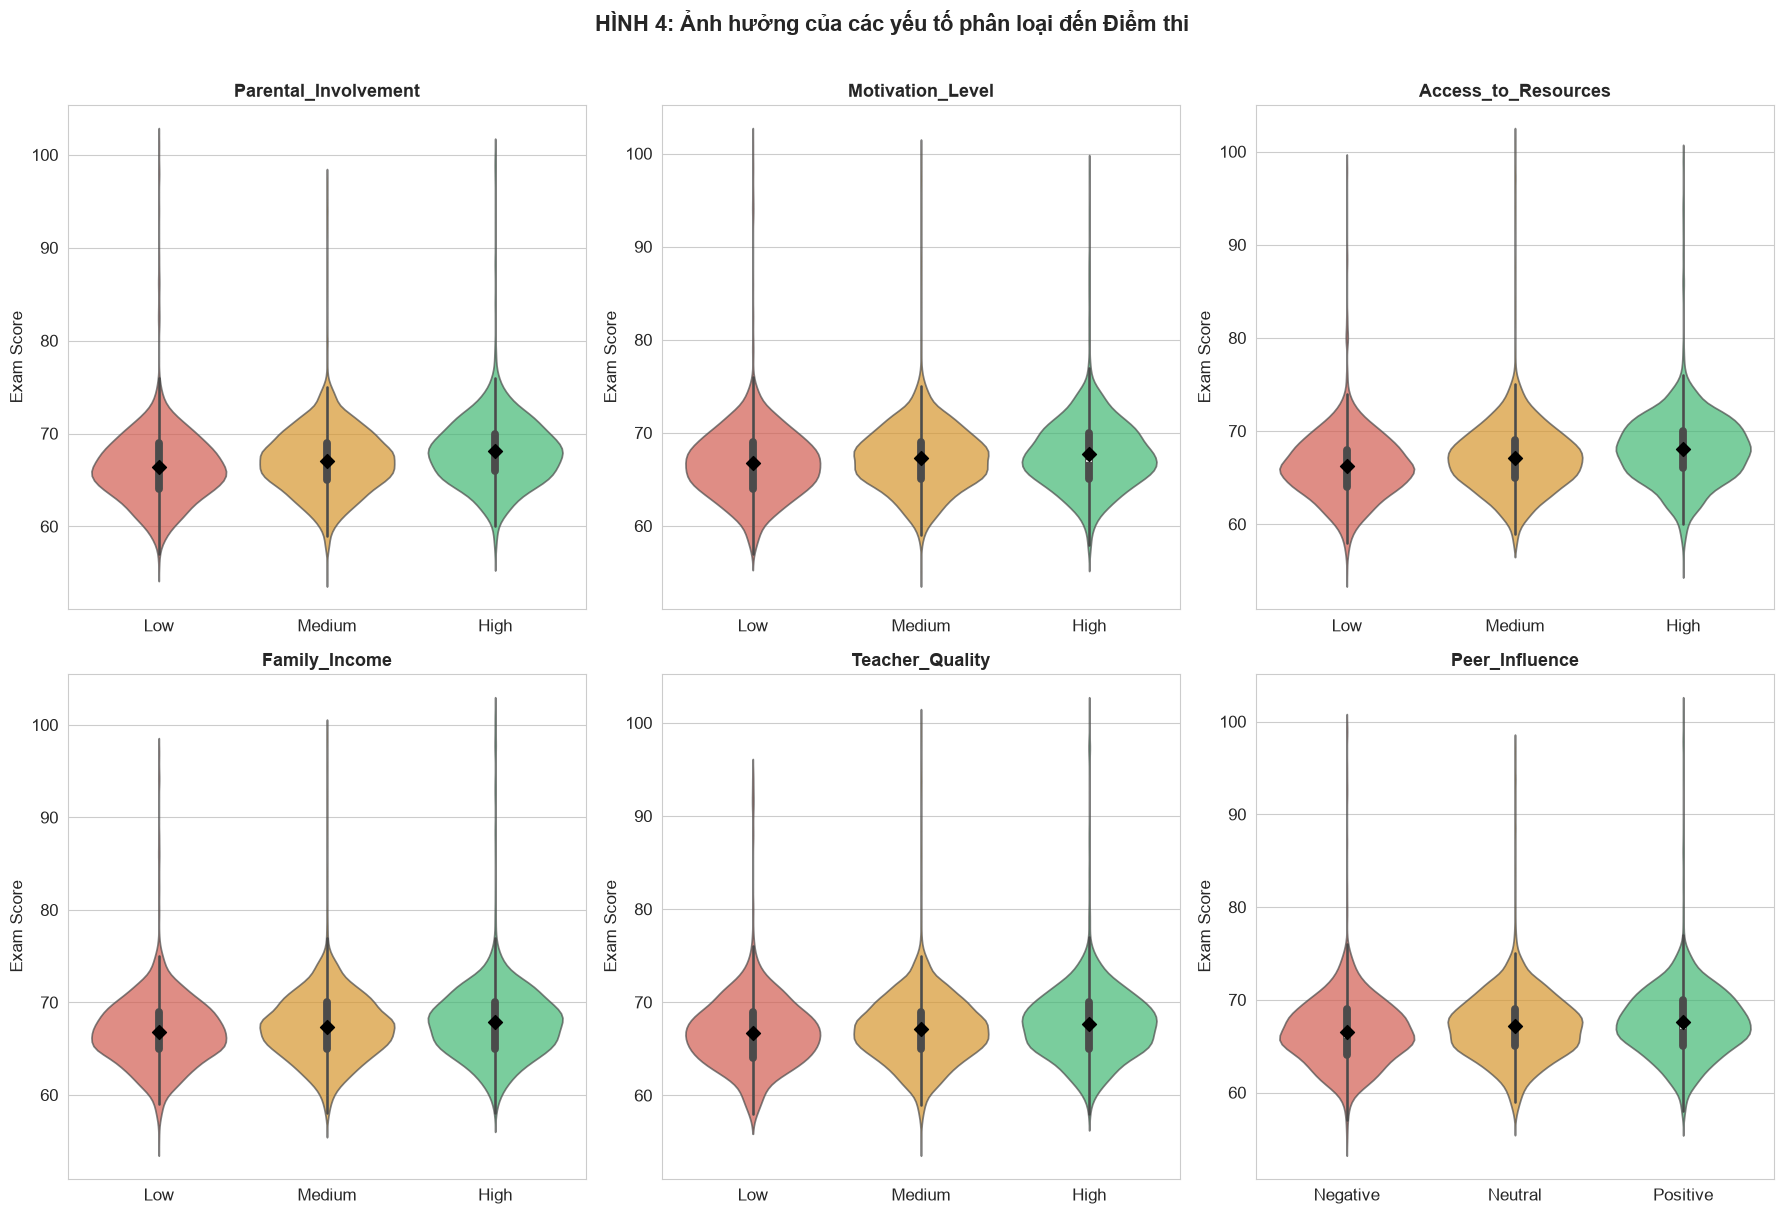


📝 Nhận xét:
   • Parental_Involvement: Nhóm 'High' có điểm cao nhất (68.09), nhóm 'Low' có điểm thấp nhất (66.36), chênh lệch = 1.73
   • Motivation_Level: Nhóm 'High' có điểm cao nhất (67.7), nhóm 'Low' có điểm thấp nhất (66.75), chênh lệch = 0.95
   • Access_to_Resources: Nhóm 'High' có điểm cao nhất (68.09), nhóm 'Low' có điểm thấp nhất (66.2), chênh lệch = 1.89
   • Family_Income: Nhóm 'High' có điểm cao nhất (67.84), nhóm 'Low' có điểm thấp nhất (66.85), chênh lệch = 0.99
   • Teacher_Quality: Nhóm 'High' có điểm cao nhất (67.68), nhóm 'Low' có điểm thấp nhất (66.75), chênh lệch = 0.93
   • Peer_Influence: Nhóm 'Positive' có điểm cao nhất (67.62), nhóm 'Negative' có điểm thấp nhất (66.56), chênh lệch = 1.06


In [14]:
# HÌNH 4: Violin/Box plots cho các biến phân loại quan trọng
cat_vars = ['Parental_Involvement', 'Motivation_Level', 'Access_to_Resources',
            'Family_Income', 'Teacher_Quality', 'Peer_Influence']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

palette = {'Low': '#e74c3c', 'Medium': '#f39c12', 'High': '#2ecc71',
           'Positive': '#2ecc71', 'Neutral': '#f39c12', 'Negative': '#e74c3c',
           'Yes': '#2ecc71', 'No': '#e74c3c'}

for i, col in enumerate(cat_vars):
    order = None
    if col in ['Parental_Involvement', 'Motivation_Level', 'Access_to_Resources', 
               'Family_Income', 'Teacher_Quality']:
        order = ['Low', 'Medium', 'High']
    elif col == 'Peer_Influence':
        order = ['Negative', 'Neutral', 'Positive']
    
    valid_order = [o for o in (order or []) if o in df[col].dropna().unique()]
    
    sns.violinplot(data=df, x=col, y='Exam_Score', order=valid_order if valid_order else None,
                   palette=palette, inner='box', ax=axes[i], alpha=0.7)
    
    # Thêm mean marker
    means = df.groupby(col)['Exam_Score'].mean()
    for j, cat in enumerate(valid_order if valid_order else df[col].dropna().unique()):
        if cat in means.index:
            idx = list(valid_order if valid_order else df[col].dropna().unique()).index(cat)
            axes[i].scatter(idx, means[cat], color='black', s=50, zorder=5, marker='D')
    
    axes[i].set_title(f'{col}', fontweight='bold', fontsize=13)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Exam Score')

plt.suptitle('HÌNH 4: Ảnh hưởng của các yếu tố phân loại đến Điểm thi', 
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print("\n📝 Nhận xét:")
for col in cat_vars:
    group_means = df.groupby(col)['Exam_Score'].mean().round(2)
    best = group_means.idxmax()
    worst = group_means.idxmin()
    diff = group_means.max() - group_means.min()
    print(f"   • {col}: Nhóm '{best}' có điểm cao nhất ({group_means[best]}), "
          f"nhóm '{worst}' có điểm thấp nhất ({group_means[worst]}), chênh lệch = {diff:.2f}")

### 📊 Hình 5: Phân phối điểm thi theo Giới tính và Loại trường

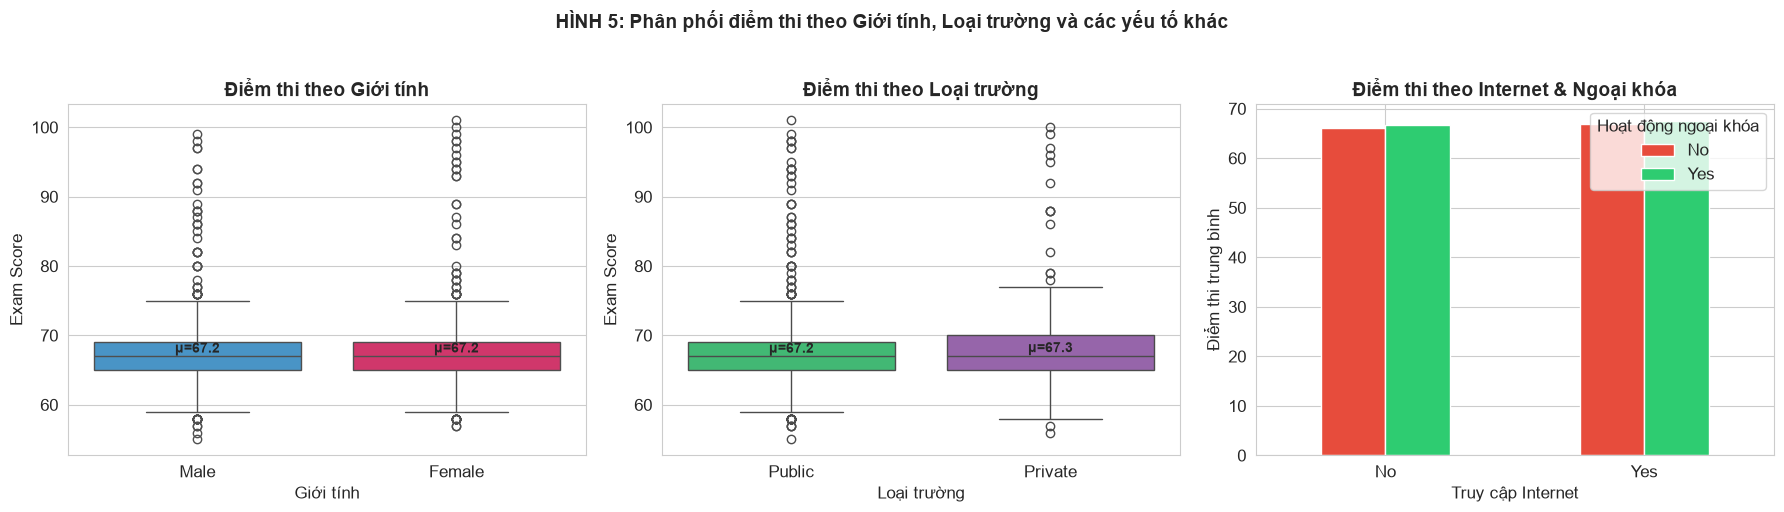


📝 Nhận xét:
   • Điểm thi trung bình Nam: 67.23, Nữ: 67.24
   • Điểm thi trung bình Trường công: 67.21, Trường tư: 67.29


In [15]:
# HÌNH 5: Grouped analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gender vs Exam Score
sns.boxplot(data=df, x='Gender', y='Exam_Score', palette=['#3498db', '#e91e63'], ax=axes[0])
axes[0].set_title('Điểm thi theo Giới tính', fontweight='bold')
axes[0].set_xlabel('Giới tính')
axes[0].set_ylabel('Exam Score')
for gender in df['Gender'].unique():
    mean_val = df[df['Gender']==gender]['Exam_Score'].mean()
    axes[0].text(list(df['Gender'].unique()).index(gender), mean_val + 0.3, 
                f'μ={mean_val:.1f}', ha='center', fontweight='bold', fontsize=10)

# School Type vs Exam Score  
sns.boxplot(data=df, x='School_Type', y='Exam_Score', palette=['#2ecc71', '#9b59b6'], ax=axes[1])
axes[1].set_title('Điểm thi theo Loại trường', fontweight='bold')
axes[1].set_xlabel('Loại trường')
axes[1].set_ylabel('Exam Score')
for stype in df['School_Type'].unique():
    mean_val = df[df['School_Type']==stype]['Exam_Score'].mean()
    axes[1].text(list(df['School_Type'].unique()).index(stype), mean_val + 0.3,
                f'μ={mean_val:.1f}', ha='center', fontweight='bold', fontsize=10)

# Internet Access & Extracurricular
cross = df.groupby(['Internet_Access', 'Extracurricular_Activities'])['Exam_Score'].mean().unstack()
cross.plot(kind='bar', ax=axes[2], color=['#e74c3c', '#2ecc71'], edgecolor='white')
axes[2].set_title('Điểm thi theo Internet & Ngoại khóa', fontweight='bold')
axes[2].set_xlabel('Truy cập Internet')
axes[2].set_ylabel('Điểm thi trung bình')
axes[2].legend(title='Hoạt động ngoại khóa')
axes[2].tick_params(axis='x', rotation=0)

plt.suptitle('HÌNH 5: Phân phối điểm thi theo Giới tính, Loại trường và các yếu tố khác', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n📝 Nhận xét:")
print(f"   • Điểm thi trung bình Nam: {df[df['Gender']=='Male']['Exam_Score'].mean():.2f}, "
      f"Nữ: {df[df['Gender']=='Female']['Exam_Score'].mean():.2f}")
print(f"   • Điểm thi trung bình Trường công: {df[df['School_Type']=='Public']['Exam_Score'].mean():.2f}, "
      f"Trường tư: {df[df['School_Type']=='Private']['Exam_Score'].mean():.2f}")

### 📊 Hình 6: Phân phối các biến số chính

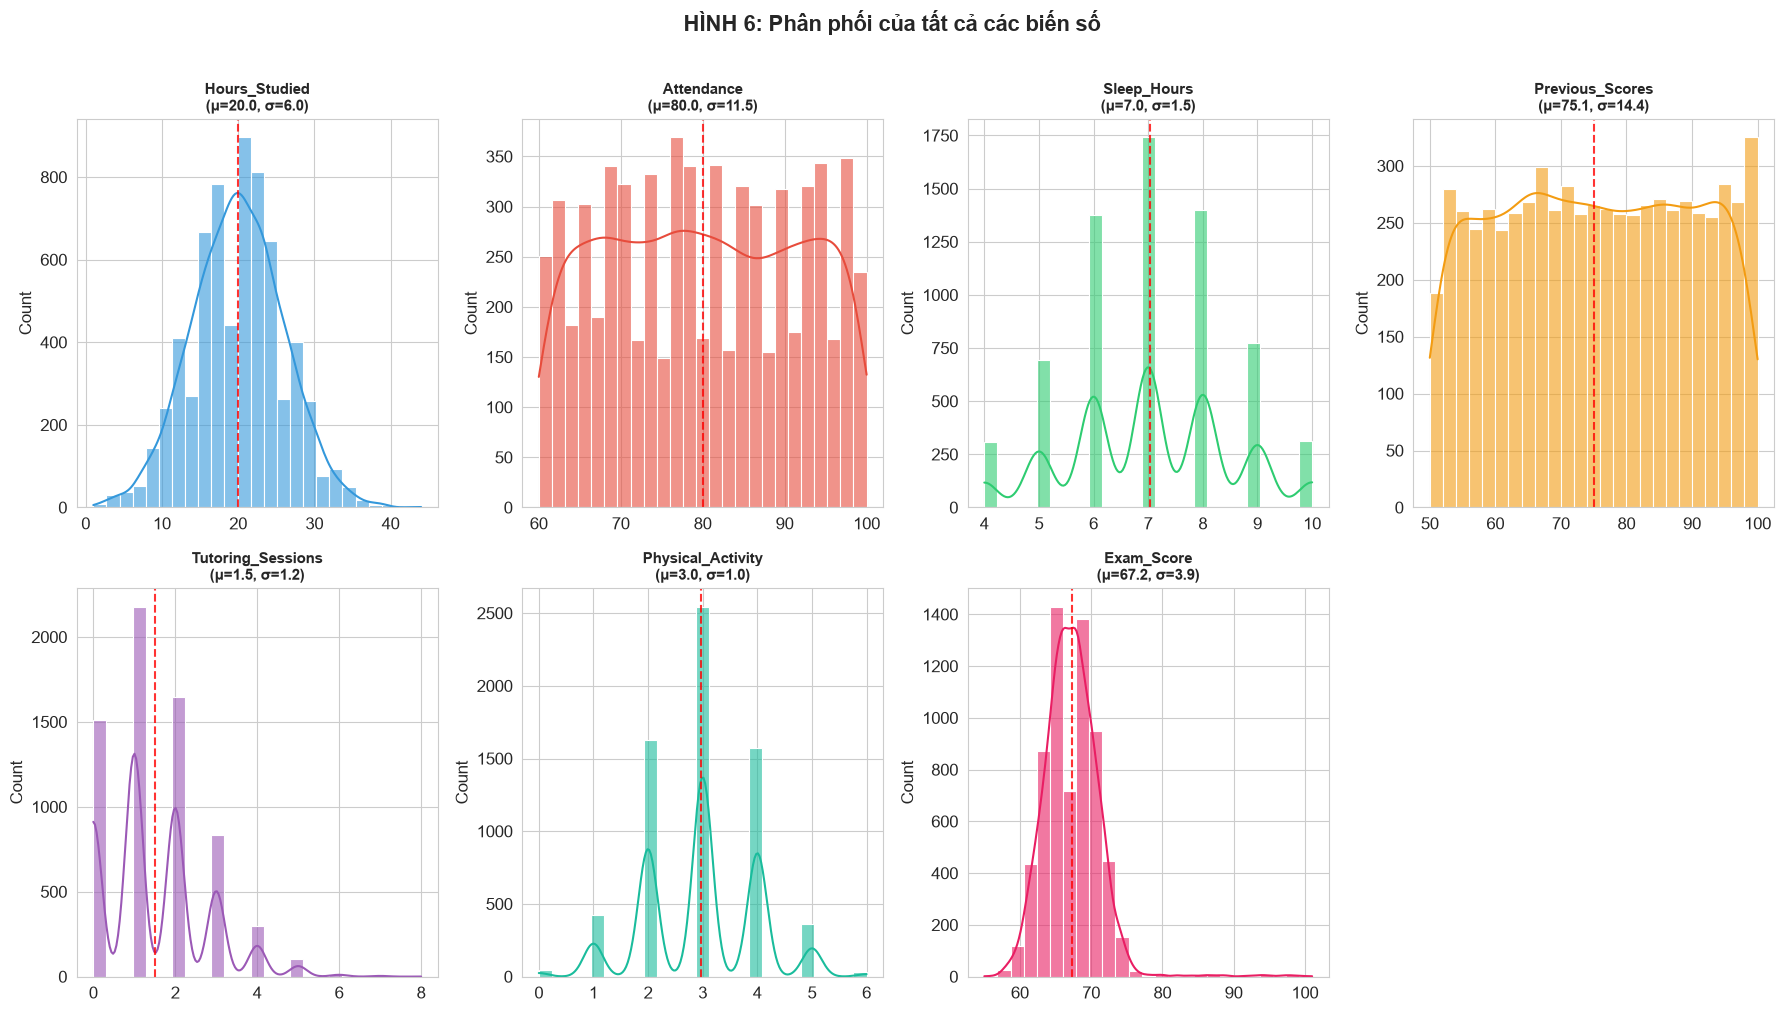

In [16]:
# HÌNH 6: Distribution plots cho các biến số
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c', '#e91e63']

for i, col in enumerate(numeric_cols):
    if i < len(axes):
        sns.histplot(data=df, x=col, kde=True, color=colors[i % len(colors)], 
                     alpha=0.6, ax=axes[i], bins=25)
        axes[i].axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5, alpha=0.8)
        axes[i].set_title(f'{col}\n(μ={df[col].mean():.1f}, σ={df[col].std():.1f})', 
                         fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('HÌNH 6: Phân phối của tất cả các biến số', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 📊 Hình 7: Pairplot - Quan hệ giữa các biến số chính

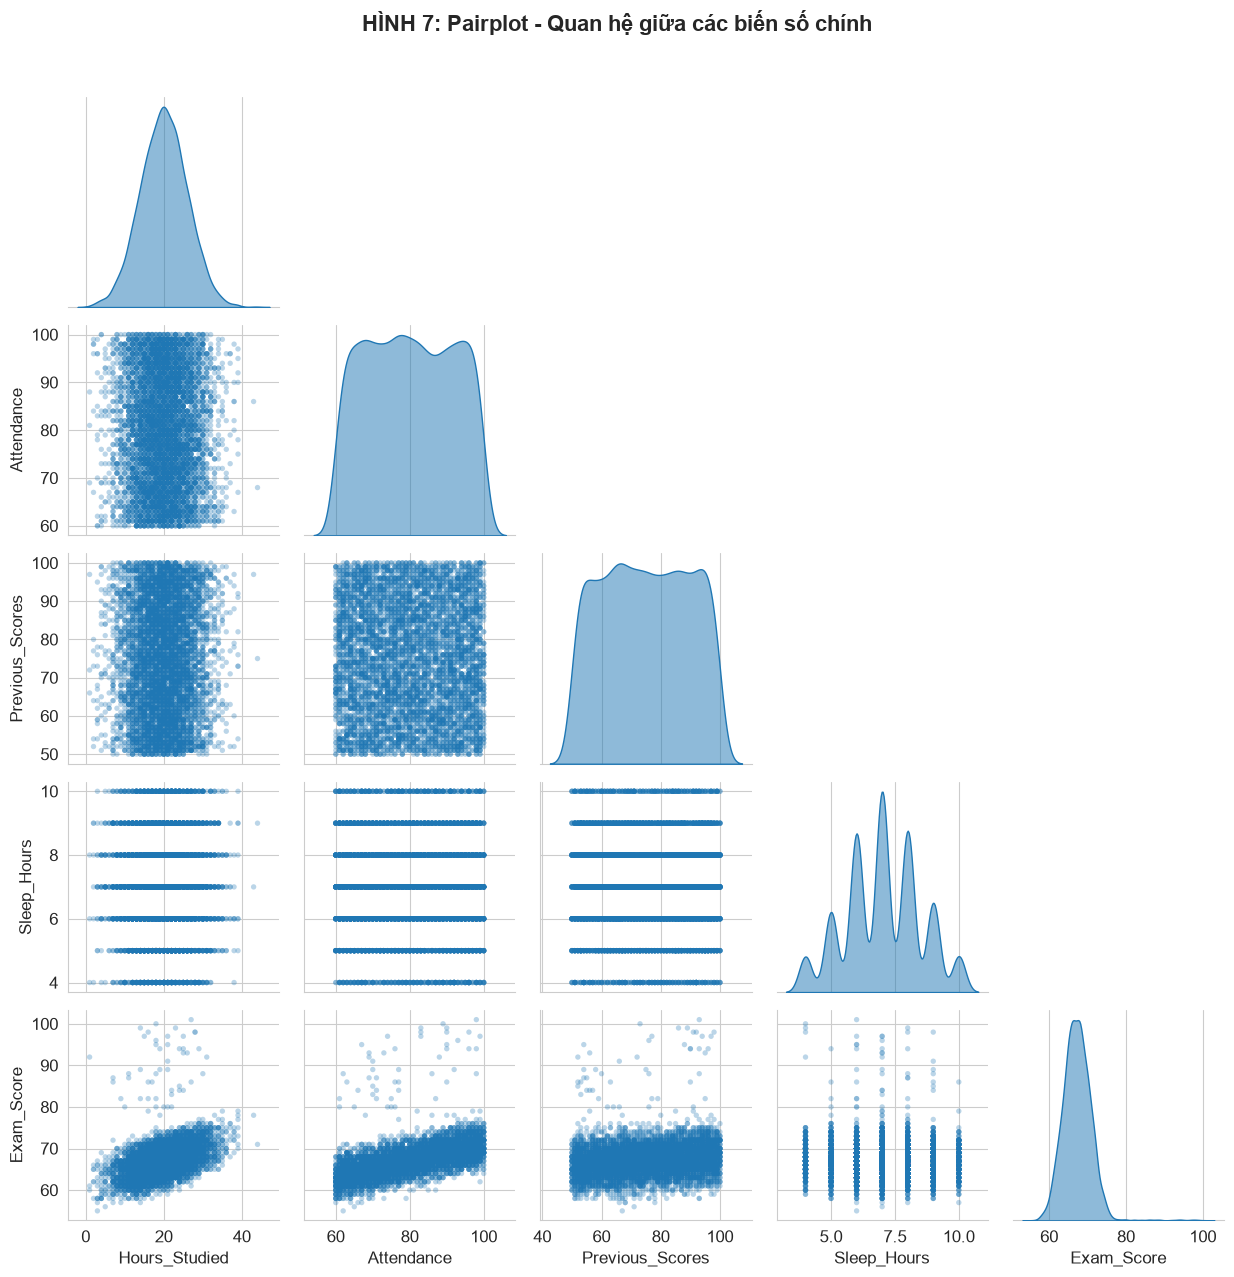

In [17]:
# HÌNH 7: Pairplot cho các biến số quan trọng nhất
key_vars = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours', 'Exam_Score']

g = sns.pairplot(df[key_vars], diag_kind='kde', 
                 plot_kws={'alpha': 0.3, 's': 15, 'edgecolor': 'none'},
                 diag_kws={'fill': True, 'alpha': 0.5},
                 corner=True)
g.figure.suptitle('HÌNH 7: Pairplot - Quan hệ giữa các biến số chính', 
                  fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Nghiên cứu mối quan hệ và mô hình giữa các biến

### 6.1. Phân tích ảnh hưởng tổng hợp

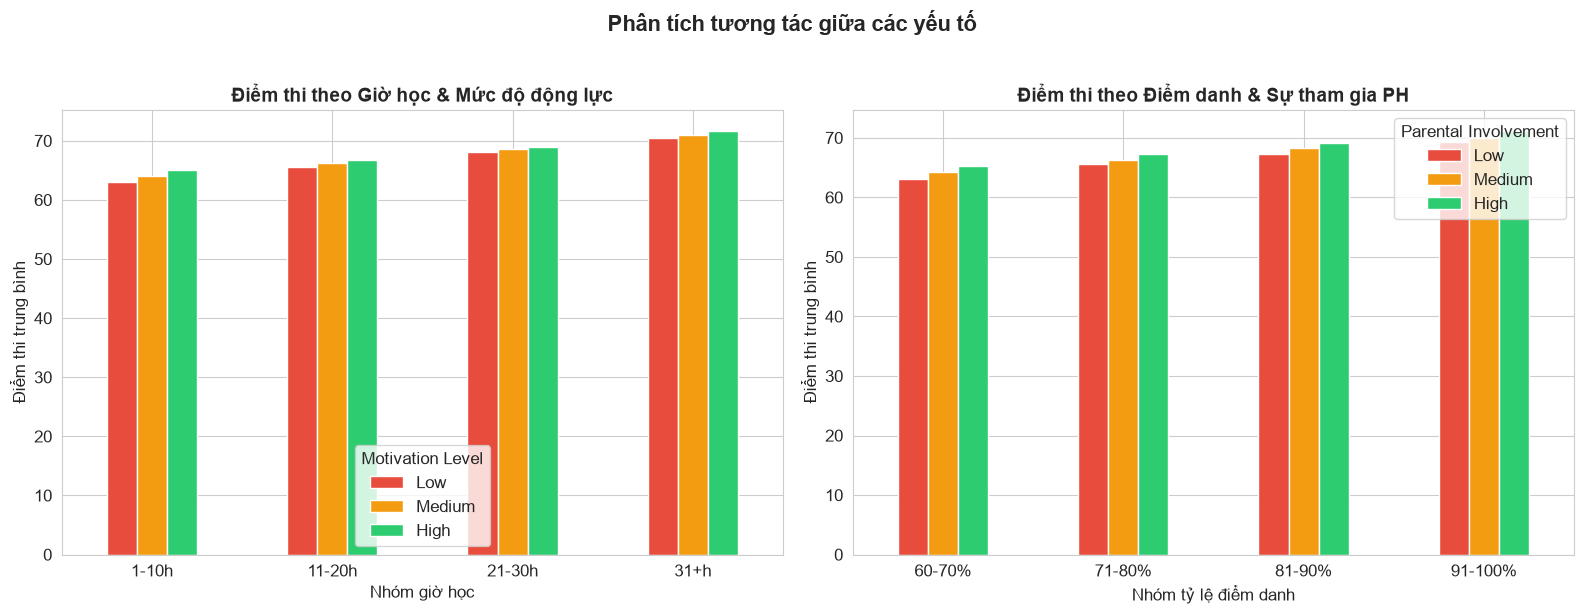


📝 Nhận xét:
   • Sinh viên học nhiều giờ VÀ có động lực cao đạt điểm cao nhất.
   • Sự tham gia của phụ huynh cũng tương tác tích cực với tỷ lệ điểm danh.
   → Các yếu tố không hoạt động độc lập mà có tác động tổng hợp lên kết quả học tập.


In [18]:
# Phân tích ảnh hưởng tổng hợp: Giờ học + Động lực → Điểm thi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Hours Studied binned + Motivation
df['Hours_Group'] = pd.cut(df['Hours_Studied'], bins=[0, 10, 20, 30, 50], 
                           labels=['1-10h', '11-20h', '21-30h', '31+h'])

pivot1 = df.groupby(['Hours_Group', 'Motivation_Level'])['Exam_Score'].mean().unstack()
pivot1 = pivot1[['Low', 'Medium', 'High']]
pivot1.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='white')
axes[0].set_title('Điểm thi theo Giờ học & Mức độ động lực', fontweight='bold')
axes[0].set_xlabel('Nhóm giờ học')
axes[0].set_ylabel('Điểm thi trung bình')
axes[0].legend(title='Motivation Level')
axes[0].tick_params(axis='x', rotation=0)

# Attendance binned + Parental Involvement
df['Attend_Group'] = pd.cut(df['Attendance'], bins=[59, 70, 80, 90, 100],
                            labels=['60-70%', '71-80%', '81-90%', '91-100%'])

pivot2 = df.groupby(['Attend_Group', 'Parental_Involvement'])['Exam_Score'].mean().unstack()
pivot2 = pivot2[['Low', 'Medium', 'High']]
pivot2.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#f39c12', '#2ecc71'], edgecolor='white')
axes[1].set_title('Điểm thi theo Điểm danh & Sự tham gia PH', fontweight='bold')
axes[1].set_xlabel('Nhóm tỷ lệ điểm danh')
axes[1].set_ylabel('Điểm thi trung bình')
axes[1].legend(title='Parental Involvement')
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Phân tích tương tác giữa các yếu tố', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n📝 Nhận xét:")
print("   • Sinh viên học nhiều giờ VÀ có động lực cao đạt điểm cao nhất.")
print("   • Sự tham gia của phụ huynh cũng tương tác tích cực với tỷ lệ điểm danh.")
print("   → Các yếu tố không hoạt động độc lập mà có tác động tổng hợp lên kết quả học tập.")

### 6.2. Phân tích tương quan chi tiết và kiểm định thống kê

In [19]:
from scipy import stats

print("=" * 70)
print("📊 KIỂM ĐỊNH THỐNG KÊ - ANOVA (So sánh trung bình nhóm)")
print("=" * 70)
print()

test_vars = ['Motivation_Level', 'Parental_Involvement', 'Access_to_Resources',
             'Family_Income', 'Teacher_Quality', 'Peer_Influence',
             'Gender', 'School_Type', 'Internet_Access', 'Extracurricular_Activities',
             'Learning_Disabilities']

results = []
for col in test_vars:
    groups = [group['Exam_Score'].values for name, group in df.groupby(col) if len(group) > 1]
    if len(groups) >= 2:
        if len(groups) == 2:
            stat, pvalue = stats.ttest_ind(groups[0], groups[1])
            test_name = 'T-test'
        else:
            stat, pvalue = stats.f_oneway(*groups)
            test_name = 'ANOVA'
        results.append({
            'Biến': col,
            'Kiểm định': test_name,
            'Statistic': round(stat, 4),
            'p-value': f'{pvalue:.6f}',
            'Kết luận': '✅ Có ý nghĩa (p<0.05)' if pvalue < 0.05 else '❌ Không có ý nghĩa'
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print("\n📝 Nhận xét:")
sig_vars = [r['Biến'] for r in results if '✅' in r['Kết luận']]
nonsig_vars = [r['Biến'] for r in results if '❌' in r['Kết luận']]
if sig_vars:
    print(f"   • Các yếu tố có ảnh hưởng có ý nghĩa thống kê đến Điểm thi (p<0.05):")
    for v in sig_vars:
        print(f"     - {v}")
if nonsig_vars:
    print(f"   • Các yếu tố KHÔNG có ảnh hưởng có ý nghĩa thống kê:")
    for v in nonsig_vars:
        print(f"     - {v}")

📊 KIỂM ĐỊNH THỐNG KÊ - ANOVA (So sánh trung bình nhóm)

                      Biến Kiểm định  Statistic  p-value              Kết luận
          Motivation_Level     ANOVA    25.7168 0.000000 ✅ Có ý nghĩa (p<0.05)
      Parental_Involvement     ANOVA    84.4877 0.000000 ✅ Có ý nghĩa (p<0.05)
       Access_to_Resources     ANOVA    98.0044 0.000000 ✅ Có ý nghĩa (p<0.05)
             Family_Income     ANOVA    29.7939 0.000000 ✅ Có ý nghĩa (p<0.05)
           Teacher_Quality     ANOVA    19.6394 0.000000 ✅ Có ý nghĩa (p<0.05)
            Peer_Influence     ANOVA    34.0521 0.000000 ✅ Có ý nghĩa (p<0.05)
                    Gender    T-test     0.1652 0.868815    ❌ Không có ý nghĩa
               School_Type    T-test     0.7188 0.472318    ❌ Không có ý nghĩa
           Internet_Access    T-test    -4.1890 0.000028 ✅ Có ý nghĩa (p<0.05)
Extracurricular_Activities    T-test    -5.2433 0.000000 ✅ Có ý nghĩa (p<0.05)
     Learning_Disabilities    T-test     6.9385 0.000000 ✅ Có ý nghĩa (p<0.

### 6.3. Xây dựng mô hình hồi quy tuyến tính đơn giản

📊 MÔ HÌNH HỒI QUY TUYẾN TÍNH

   R² Score: 0.6466
   → Mô hình giải thích được 64.7% phương sai của Exam_Score

   Intercept: 39.9598

📊 Hệ số hồi quy (sắp xếp theo mức độ ảnh hưởng):
                              Biến  Hệ số (Coefficient)
           Internet_Access_encoded             0.941052
     Learning_Disabilities_encoded            -0.867323
Extracurricular_Activities_encoded             0.544401
            Peer_Influence_encoded             0.534686
                 Tutoring_Sessions             0.492709
        Distance_from_Home_encoded             0.491778
      Parental_Involvement_encoded            -0.430546
       Access_to_Resources_encoded            -0.403088
                     Hours_Studied             0.291695
           Teacher_Quality_encoded            -0.231385
                        Attendance             0.197612
                 Physical_Activity             0.165436
  Parental_Education_Level_encoded             0.160805
             Family_Income_encod

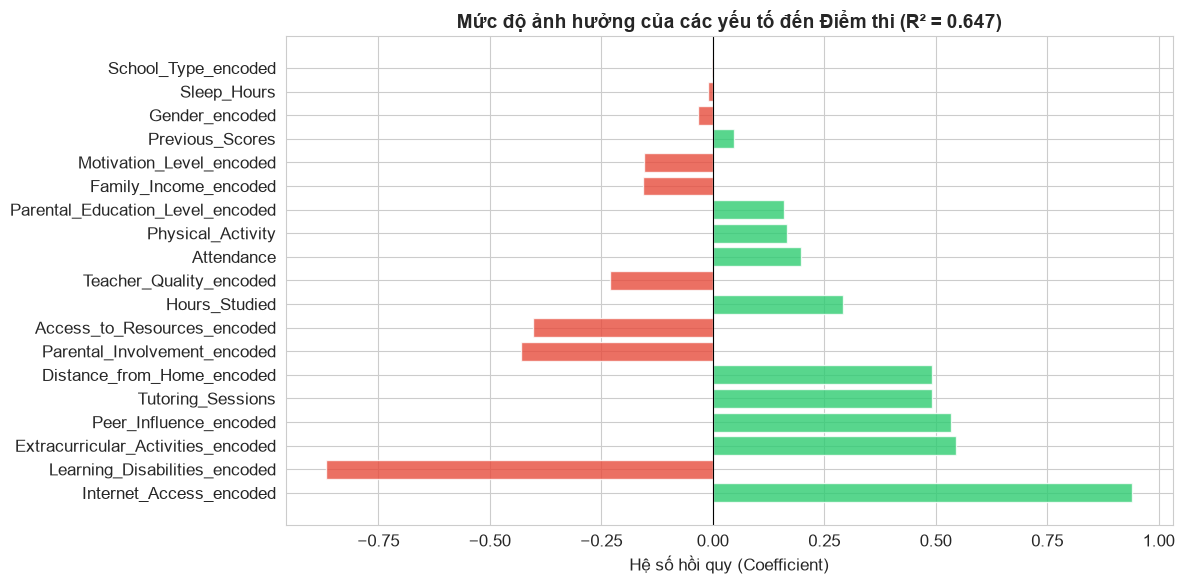


📝 Nhận xét:
   • Top 3 yếu tố ảnh hưởng mạnh nhất đến điểm thi:
     - Internet_Access_encoded: hệ số = 0.9411 (tích cực)
     - Learning_Disabilities_encoded: hệ số = -0.8673 (tiêu cực)
     - Extracurricular_Activities_encoded: hệ số = 0.5444 (tích cực)


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder

# Chuẩn bị dữ liệu
df_model = df.dropna().copy()

# Mã hóa biến phân loại
le_dict = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_model[col + '_encoded'] = le.fit_transform(df_model[col])
    le_dict[col] = le

# Chọn các features
features = numeric_cols[:-1]  # Bỏ Exam_Score
encoded_features = [col + '_encoded' for col in categorical_cols]
all_features = features + encoded_features

X = df_model[all_features]
y = df_model['Exam_Score']

# Hồi quy tuyến tính
model = LinearRegression()
model.fit(X, y)

# Feature importance
importance = pd.DataFrame({
    'Biến': all_features,
    'Hệ số (Coefficient)': model.coef_
}).sort_values('Hệ số (Coefficient)', key=abs, ascending=False)

print("=" * 60)
print("📊 MÔ HÌNH HỒI QUY TUYẾN TÍNH")
print("=" * 60)
print(f"\n   R² Score: {model.score(X, y):.4f}")
print(f"   → Mô hình giải thích được {model.score(X, y)*100:.1f}% phương sai của Exam_Score")
print(f"\n   Intercept: {model.intercept_:.4f}")
print(f"\n📊 Hệ số hồi quy (sắp xếp theo mức độ ảnh hưởng):")
print(importance.to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in importance['Hệ số (Coefficient)'].values]
bars = ax.barh(importance['Biến'], importance['Hệ số (Coefficient)'], color=colors, alpha=0.8)
ax.set_title(f'Mức độ ảnh hưởng của các yếu tố đến Điểm thi (R² = {model.score(X, y):.3f})', 
             fontweight='bold', fontsize=14)
ax.set_xlabel('Hệ số hồi quy (Coefficient)')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print("\n📝 Nhận xét:")
top3 = importance.head(3)
print(f"   • Top 3 yếu tố ảnh hưởng mạnh nhất đến điểm thi:")
for _, row in top3.iterrows():
    direction = "tích cực" if row['Hệ số (Coefficient)'] > 0 else "tiêu cực"
    print(f"     - {row['Biến']}: hệ số = {row['Hệ số (Coefficient)']:.4f} ({direction})")

## 7. Kết luận tổng hợp

---

### 📋 Tóm tắt phân tích

**1. Tổng quan dữ liệu:**
- Tập dữ liệu gồm **6,607 sinh viên** với **20 biến** (7 biến số, 13 biến phân loại).
- Dữ liệu tương đối sạch: không có dòng trùng lặp, chỉ có 3 cột có giá trị thiếu (Teacher_Quality, Parental_Education_Level, Distance_from_Home) với tỷ lệ thấp (~1-1.4%).

**2. Chất lượng dữ liệu:**
- Kiểu dữ liệu phù hợp cho từng biến.
- Một số giá trị bất thường (outliers) được phát hiện nhưng ở mức chấp nhận được.

**3. Các yếu tố ảnh hưởng chính đến Điểm thi:**
- **Số giờ học (Hours_Studied)** và **Tỷ lệ điểm danh (Attendance)** là hai yếu tố số có tương quan mạnh nhất.
- **Điểm trước đó (Previous_Scores)** cũng có ảnh hưởng đáng kể.
- **Mức độ động lực (Motivation_Level)**, **Sự tham gia của phụ huynh**, và **Thu nhập gia đình** là các yếu tố phân loại quan trọng.

**4. Mối quan hệ giữa các biến:**
- Các yếu tố không hoạt động độc lập mà có **tác động tổng hợp** (interaction effect).
- Sinh viên có động lực cao + học nhiều giờ + điểm danh tốt đạt kết quả tốt nhất.

**5. Khuyến nghị:**
- Tập trung cải thiện thời gian tự học và tỷ lệ điểm danh.
- Tăng cường sự tham gia của phụ huynh và động lực học tập.
- Hỗ trợ thêm cho nhóm sinh viên có thu nhập thấp và thiếu tài nguyên.

---
*Phân tích được thực hiện bằng Python với các thư viện: pandas, numpy, matplotlib, seaborn, scipy, scikit-learn.*


In [21]:
# Dọn dẹp các cột tạm
if 'Hours_Group' in df.columns:
    df.drop(columns=['Hours_Group', 'Attend_Group'], inplace=True, errors='ignore')
print("✅ Phân tích hoàn tất!")

✅ Phân tích hoàn tất!
